In [1]:
import sys
sys.path.append('../scripts')
from utils.cftp_func import *
import glob
from scipy.stats import linregress

In [2]:
julia_colors = [
    '#00A9AD',  # teal
    '#E28F41',  # orange
    '#389826',  # green
    '#9558B2',  # purple
    '#CB3C33',  # red
    '#7C7C7C',  # grey
    '#BB7DC0',  # light purple
    '#4063D8',  # blue
]
from cycler import cycler
plt.rcParams['axes.prop_cycle'] = cycler(color=julia_colors)
plt.rcParams['axes.spines.top'] = False
plt.rcParams['axes.spines.right'] = False
plt.rcParams['legend.frameon'] = False

plt.rcParams['font.size'] = 14          
plt.rcParams['axes.labelsize'] = 16     
plt.rcParams['xtick.labelsize'] = 13
plt.rcParams['ytick.labelsize'] = 13
plt.rcParams['legend.fontsize'] = 12
plt.rcParams['axes.titlesize'] = 16

In [17]:
graph_type = 'ER'
coup_type = 'gauss'
d = 4
if graph_type == 'ER' and coup_type == 'ising':
    beta_SG = np.arctanh(np.sqrt(1/d))
    beta_uni = np.arctanh(1/d)
    print(f"beta_uni = {beta_uni:.6f}, beta_SG = {beta_SG:.6f}")
elif graph_type == 'ER' and coup_type == 'gauss':
    beta_uni = solve_beta_critical_gauss(d=4)
    print(f"beta_uni = {beta_uni:.6f}")
elif graph_type == 'RR' and coup_type == 'ising':
    beta_SG = np.arctanh(np.sqrt(1/(d-1)))
    beta_uni = np.arctanh(1/(d-1))
    beta_dob = np.arctanh(1/d)
    print(f"beta_dob = {beta_dob:.6f}, beta_uni = {beta_uni:.6f}, beta_SG = {beta_SG:.6f}")
elif graph_type == 'EA2D' and coup_type == 'ising':
    beta_uni = np.arctanh(1/3)
    beta_DS = 0.58
    print(f"beta_uni = {beta_uni:.6f}")
elif graph_type == 'EA3D' and coup_type == 'ising':
    beta_uni = np.arctanh(1/5)
    beta_DS = 0.33
    print(f"beta_uni = {beta_uni:.6f}")


beta_uni = 0.334882


In [18]:
if graph_type == 'ER' and coup_type in ('ising','gauss'):
    folder_data = f"perm/{graph_type}_{coup_type}"
else:
    folder_data = "tmp"
dfs = [pd.read_csv(f) for f in glob.glob(f'../results/{folder_data}/coal_time_DS_{graph_type}_{coup_type}_d{d}_beta*.csv')]
df = pd.concat(dfs, ignore_index=True)

if graph_type in ('EA2D', 'F2D'):
    print("betas:", sorted(df['beta'].unique()), "\nL:", sorted(df['N'].unique()), "\nsizes:", sorted(df['N'].unique()**2))
elif graph_type in ('EA3D', 'F3D'):
    print("betas:", sorted(df['beta'].unique()), "\nL:", sorted(df['N'].unique()), "\nsizes:", sorted(df['N'].unique()**3))
else:
    print("betas:", sorted(df['beta'].unique()), "\nsizes:", sorted(df['N'].unique()))
df

betas: [0.32, 0.33, 0.331, 0.333, 0.336, 0.34, 0.35] 
sizes: [100, 300, 1000, 3000, 10000, 30000, 100000, 300000, 1000000]


,beta,sampler,lazy,n_configs,n_runs,max_iter,N,n_coal,mean_coal_time,std_coal_time
0,0.333,F_beta_Glauber,False,2,50,1000000000,100,50,2.136240e+03,1.972785e+03
1,0.333,F_beta_Glauber,False,2,50,1000000000,1000,50,8.339454e+04,5.292236e+04
2,0.333,F_beta_Glauber,False,2,50,1000000000,10000,50,2.464186e+06,9.743812e+05
3,0.333,F_beta_Glauber,False,2,50,1000000000,100000,50,6.878921e+07,2.837272e+07
4,0.333,F_beta_Glauber,False,2,50,1000000000,300000,50,3.244170e+08,1.374242e+08
5,0.333,F_beta_Glauber,False,2,50,1000000000,300,50,1.377156e+04,7.613294e+03
6,0.333,F_beta_Glauber,False,2,50,1000000000,3000,50,4.776495e+05,2.554393e+05
7,0.333,F_beta_Glauber,False,2,50,1000000000,30000,50,1.285223e+07,5.705751e+06
8,0.331,F_beta_Glauber,False,2,50,1000000000,100,50,2.136080e+03,1.418401e+03
9,0.331,F_beta_Glauber,False,2,50,1000000000,1000,50,8.016050e+04,4.818358e+04


# Proba of coalescence

In [19]:
n_configs_plot = 2
max_iter_plot = 10**9
if graph_type == 'ER' and coup_type in ('ising','gauss'):
    N_plot = [10**3,10**4,10**5, 3*10**5]#,10**6]
    mask = (
        (df['N'].isin(N_plot)) &
        (df['n_configs'] == n_configs_plot) &
        (df['max_iter'] == max_iter_plot) 
    )
elif graph_type == 'EA2D' and coup_type == 'ising':
    N_plot = [30,100,300,500,1000]
    mask = (
        (df['N'].isin(N_plot)) &
        (df['n_configs'] == n_configs_plot) &
        (df['max_iter'] == max_iter_plot) 
    )
else:
    mask = (
        (df['n_configs'] == n_configs_plot) &
        (df['max_iter'] == max_iter_plot) 
    )
df_filtered = df[mask]
df_filtered

,beta,sampler,lazy,n_configs,n_runs,max_iter,N,n_coal,mean_coal_time,std_coal_time
1,0.333,F_beta_Glauber,False,2,50,1000000000,1000,50,8.339454e+04,5.292236e+04
2,0.333,F_beta_Glauber,False,2,50,1000000000,10000,50,2.464186e+06,9.743812e+05
3,0.333,F_beta_Glauber,False,2,50,1000000000,100000,50,6.878921e+07,2.837272e+07
4,0.333,F_beta_Glauber,False,2,50,1000000000,300000,50,3.244170e+08,1.374242e+08
9,0.331,F_beta_Glauber,False,2,50,1000000000,1000,50,8.016050e+04,4.818358e+04
10,0.331,F_beta_Glauber,False,2,50,1000000000,10000,50,2.644170e+06,1.253755e+06
11,0.331,F_beta_Glauber,False,2,50,1000000000,100000,50,5.248618e+07,1.686552e+07
12,0.331,F_beta_Glauber,False,2,50,1000000000,300000,50,2.459394e+08,8.163703e+07
17,0.320,F_beta_Glauber,False,2,50,1000000000,1000,50,7.022232e+04,5.024458e+04
18,0.320,F_beta_Glauber,False,2,50,1000000000,10000,50,1.544744e+06,5.671520e+05


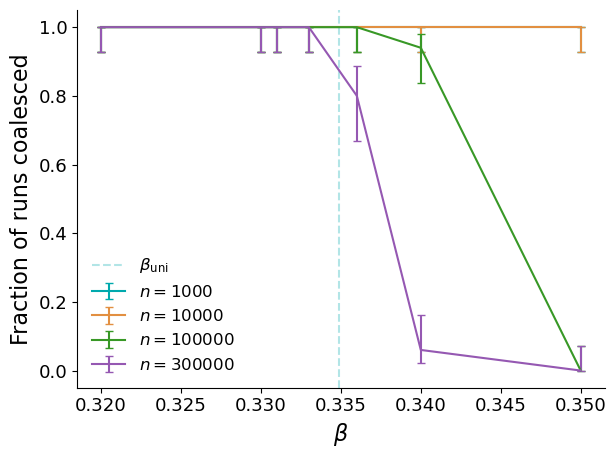

In [20]:
fig, ax = plt.subplots()

for N in sorted(df_filtered['N'].unique()):
    sub_df = df_filtered[df_filtered['N'] == N].sort_values('beta')
    k = sub_df['n_coal'].values
    n = sub_df['n_runs'].values
    p, err_down, err_up = wilson_interval(k, n)
    if graph_type == 'EA2D' or graph_type == 'F2D':
        ax.errorbar(sub_df['beta'], p, yerr=[err_down, err_up],label=rf'$n={N**2}$', capsize=3)
    elif graph_type == 'EA3D' or graph_type == 'F3D':
        ax.errorbar(sub_df['beta'], p, yerr=[err_down, err_up],label=rf'$n={N**3}$', capsize=3)
    else:
        ax.errorbar(sub_df['beta'], p, yerr=[err_down, err_up],label=rf'$n={N}$', capsize=3)
ax.axvline(beta_uni, linestyle='--', alpha=0.3, label=rf'$\beta_\mathrm{{uni}}$')
ax.set_xlabel(rf'$\beta$')
ax.set_ylabel('Fraction of runs coalesced')
ax.legend()
plt.tight_layout()
plt.show()

In [21]:
fig.savefig(f'../results/{folder_data}/coal_DS_frac_{graph_type}_{coup_type}_d{d}.pdf', bbox_inches='tight')

# Scaling of coalescence times

In [22]:
max_iter_plot = 10**9
n_configs_plot = 2
mask = (
    (df['n_coal'] == df['n_runs']) & # plot only beta values for which every run has coalesced (for unbiased averages)
    (df['n_configs'] == n_configs_plot) &
    (df['max_iter'] == max_iter_plot) 
)
df_filtered = df[mask]
#df_filtered

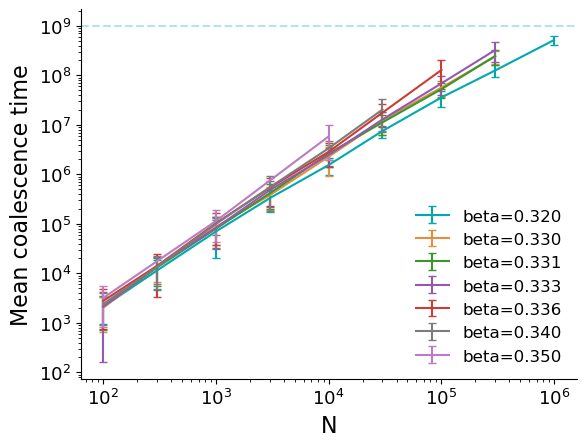

In [23]:
mask = (
    (df['sampler'] == 'F_beta_Glauber') &
    (df['lazy'] == False) &
    (df['n_configs'] == n_configs_plot) &
    (df['n_coal'] == df['n_runs'])
)
df_filtered = df[mask]

betas_to_exclude = []
for beta in sorted(df_filtered['beta'].unique()):
    if beta in betas_to_exclude:
        continue    
    sub_df = df_filtered[df_filtered['beta'] == beta].sort_values('N')
    N = sub_df['N'].values
    T = sub_df['mean_coal_time'].values
    sT = sub_df['std_coal_time'].values
    plt.errorbar(N, T,
                yerr=sT,
                label=f'beta={beta:.3f}',
                capsize=3)

plt.axhline(10**9, linestyle='--', alpha=0.3)
plt.xlabel('N')
plt.ylabel('Mean coalescence time')
plt.xscale('log')
plt.yscale('log')
plt.legend()
plt.show()

In [24]:
max_iter_plot = 10**9
n_configs_plot = 2
if graph_type == 'ER' and coup_type == 'ising':
    beta_plot = [0.25,0.252,0.257,0.26] # beta selection for plotting
else:
    beta_plot = df['beta'].unique()

mask = (
    (df['n_coal'] == df['n_runs']) & # plot only beta values for which every run has coalesced (for unbiased averages)
    (df['beta'].isin(beta_plot)) &
    (df['n_configs'] == n_configs_plot) &
    (df['max_iter'] == max_iter_plot) 
)
df_filtered = df[mask]
#df_filtered

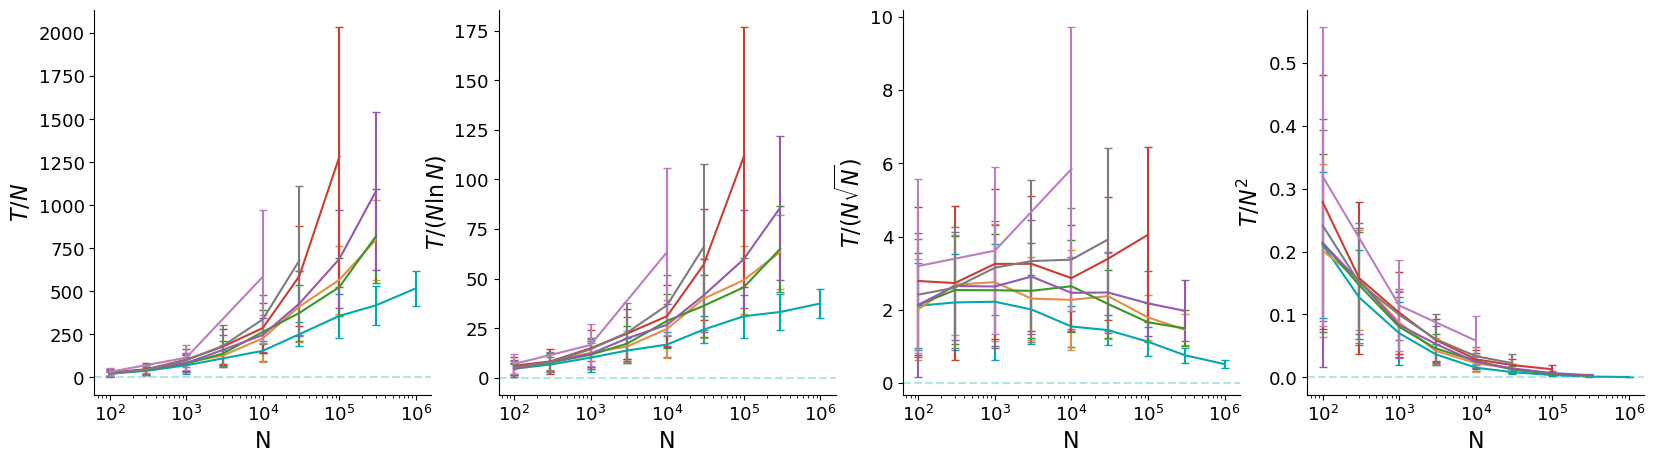

In [25]:
fig, axes = plt.subplots(1, 4, figsize=(20, 5))
scalings = {
    r'$T / N$': (lambda N, T: T / N, 
                lambda N, T, sT: sT / N),
    r'$T / (N \ln N)$': (lambda N, T: T / (N * np.log(N)), 
                          lambda N, T, sT: sT / (N * np.log(N))),
#    r'$T / (N \ln N^2)$': (lambda N, T: T / (N * np.log(N)**2), 
#                          lambda N, T, sT: sT / (N * np.log(N)**2)),
    r'$T / (N \sqrt{N})$': (lambda N, T: T / (N * np.sqrt(N)), 
                          lambda N, T, sT: sT / (N * np.sqrt(N))),
    r'$T / N^2$': (lambda N, T: T / N**2, 
                   lambda N, T, sT: sT / N**2),
}
for ax, (label, (scaling_fn, err_fn)) in zip(axes, scalings.items()):
    for beta in sorted(df_filtered['beta'].unique()):
        sub_df = df_filtered[df_filtered['beta'] == beta].sort_values('N')
        N = sub_df['N'].values
        if graph_type in ('EA2D', 'F2D'):
            N = N**2
        if graph_type in ('EA3D', 'F3D'):
            N = N**3
        T = sub_df['mean_coal_time'].values
        sT = sub_df['std_coal_time'].values
        ax.errorbar(N, scaling_fn(N, T), yerr=err_fn(N, T, sT), label=f'beta={beta:.3f}', capsize=3)
    ax.axhline(0, linestyle='--', alpha=0.3)
    ax.set_xlabel('N')
    ax.set_ylabel(label)
    ax.set_xscale('log')   
plt.show()

beta=0.320 [NlnN]: A1=47.9542 ± 5.0360, B1=-229.3026 ± 38.4094, R²=0.8358
beta=0.320 [N**D]:  C=5.6510 ± 1.2615, D=1.3481 ± 0.0231, R²=0.9979
beta=0.320 [N(lnN)²]: A2=3.5617 ± 0.2193, B2=-13.0925 ± 1.6730, R²=0.8974

beta=0.330 [NlnN]: A1=77.4374 ± 12.5238, B1=-388.2163 ± 91.6206, R²=0.7495
beta=0.330 [N**D]:  C=3.3086 ± 0.6955, D=1.4508 ± 0.0234, R²=0.9984
beta=0.330 [N(lnN)²]: A2=6.3626 ± 0.7474, B2=-27.9253 ± 5.4674, R²=0.8130

beta=0.331 [NlnN]: A1=76.5538 ± 12.2130, B1=-382.6861 ± 89.3469, R²=0.7535
beta=0.331 [N**D]:  C=3.4043 ± 0.6894, D=1.4477 ± 0.0225, R²=0.9986
beta=0.331 [N(lnN)²]: A2=6.2895 ± 0.7030, B2=-27.4438 ± 5.1432, R²=0.8259

beta=0.333 [NlnN]: A1=96.0422 ± 18.7073, B1=-493.1838 ± 136.8577, R²=0.6840
beta=0.333 [N**D]:  C=2.8573 ± 0.4382, D=1.4802 ± 0.0170, R²=0.9992
beta=0.333 [N(lnN)²]: A2=7.9156 ± 1.1857, B2=-36.5141 ± 8.6741, R²=0.7471

beta=0.336 [NlnN]: A1=118.9745 ± 33.5936, B1=-609.6181 ± 234.8819, R²=0.5740
beta=0.336 [N**D]:  C=2.2142 ± 0.2785, D=1.5444 ± 0

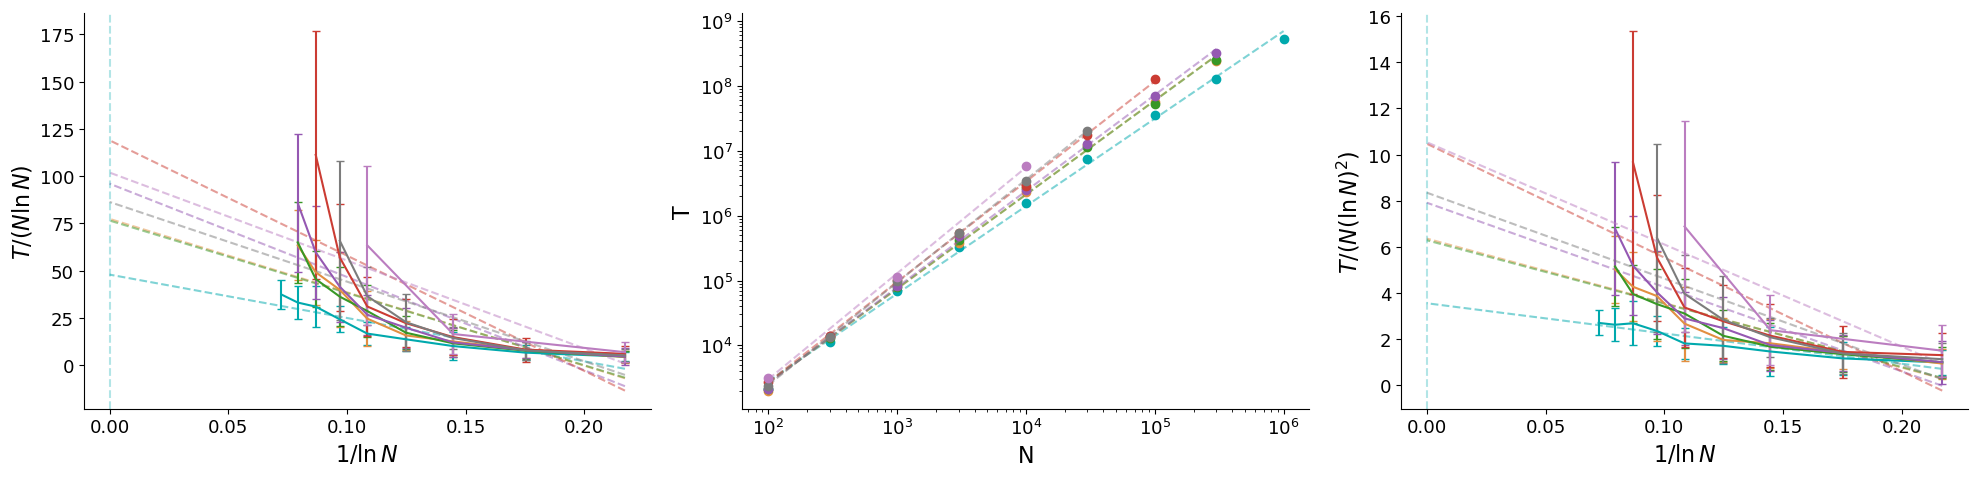

In [26]:
fig, axes = plt.subplots(1, 3, figsize=(20, 5))
fit_coeffs = {}

for beta in sorted(df_filtered['beta'].unique()):
    sub_df = df_filtered[df_filtered['beta'] == beta].sort_values('N')
    N = sub_df['N'].values
    if graph_type in ('EA2D', 'F2D'):
        N = N**2
    if graph_type in ('EA3D', 'F3D'):
        N = N**3
    T = sub_df['mean_coal_time'].values
    sT = sub_df['std_coal_time'].values

    # --- plot 1: T/(NlnN) vs 1/lnN ---
    x = 1 / np.log(N)
    y = T / (N * np.log(N))
    yerr = sT / (N * np.log(N))
    eb = axes[0].errorbar(x, y, yerr=yerr, label=f'beta={beta:.3f}', capsize=3)
    color = eb.lines[0].get_color() # reuse same color for fit line
    res1 = linregress(x, y)  # slope=B1, intercept=A1
    x_fit = np.linspace(x.max(), 0, 100)
    axes[0].plot(x_fit, res1.slope * x_fit + res1.intercept, linestyle='--', alpha=0.5, color=color)
    print(f"beta={beta:.3f} [NlnN]: A1={res1.intercept:.4f} ± {res1.intercept_stderr:.4f}, "
          f"B1={res1.slope:.4f} ± {res1.stderr:.4f}, R²={res1.rvalue**2:.4f}")

    # --- plot 2: log T vs log N ---
    res2 = linregress(np.log(N), np.log(T))
    D = res2.slope
    C = np.exp(res2.intercept)
    C_err = C * res2.intercept_stderr
    axes[1].loglog(N, T, 'o', color=color, label=f'beta={beta:.3f} (D={D:.3f})')
    axes[1].loglog(N, C * N**D, '--', alpha=0.5, color=color)
    print(f"beta={beta:.3f} [N**D]:  C={C:.4f} ± {C_err:.4f}, "
          f"D={D:.4f} ± {res2.stderr:.4f}, R²={res2.rvalue**2:.4f}")

    # --- plot 3: T/(N(lnN)^2) vs 1/lnN ---
    y3 = T / (N * np.log(N)**2)
    yerr3 = sT / (N * np.log(N)**2)
    axes[2].errorbar(x, y3, yerr=yerr3, capsize=3, color=color, label=f'beta={beta:.3f}')
    res3 = linregress(x, y3)  # intercept=A2, slope=B2
    axes[2].plot(x_fit, res3.slope * x_fit + res3.intercept, linestyle='--', alpha=0.5, color=color)
    print(f"beta={beta:.3f} [N(lnN)²]: A2={res3.intercept:.4f} ± {res3.intercept_stderr:.4f}, "
        f"B2={res3.slope:.4f} ± {res3.stderr:.4f}, R²={res3.rvalue**2:.4f}\n")

    fit_coeffs[beta] = {
        # NlnN fit 
        'A1': res1.intercept, 'A1_err': res1.intercept_stderr,
        'B1': res1.slope,     'B1_err': res1.stderr,
        'r2_NlnN': res1.rvalue**2,
        # power law fit
        'C': C,               'C_err': C_err,
        'D': D,               'D_err': res2.stderr,
        'r2_powerlaw': res2.rvalue**2,
        'A2': res3.intercept, 'A2_err': res3.intercept_stderr,
        'B2': res3.slope,     'B2_err': res3.stderr,
        'r2_NlnN2': res3.rvalue**2,
    }

axes[0].axvline(0, linestyle='--', alpha=0.3)
axes[0].set_xlabel(r'$1 / \ln N$')
axes[0].set_ylabel(r'$T / (N \ln N)$')

axes[1].set_xlabel('N')
axes[1].set_ylabel('T')

axes[2].axvline(0, linestyle='--', alpha=0.3)
axes[2].set_xlabel(r'$1 / \ln N$')
axes[2].set_ylabel(r'$T / (N (\ln N)^2)$')

plt.tight_layout()
plt.show()

beta_sel_list= [0.33, 0.34]


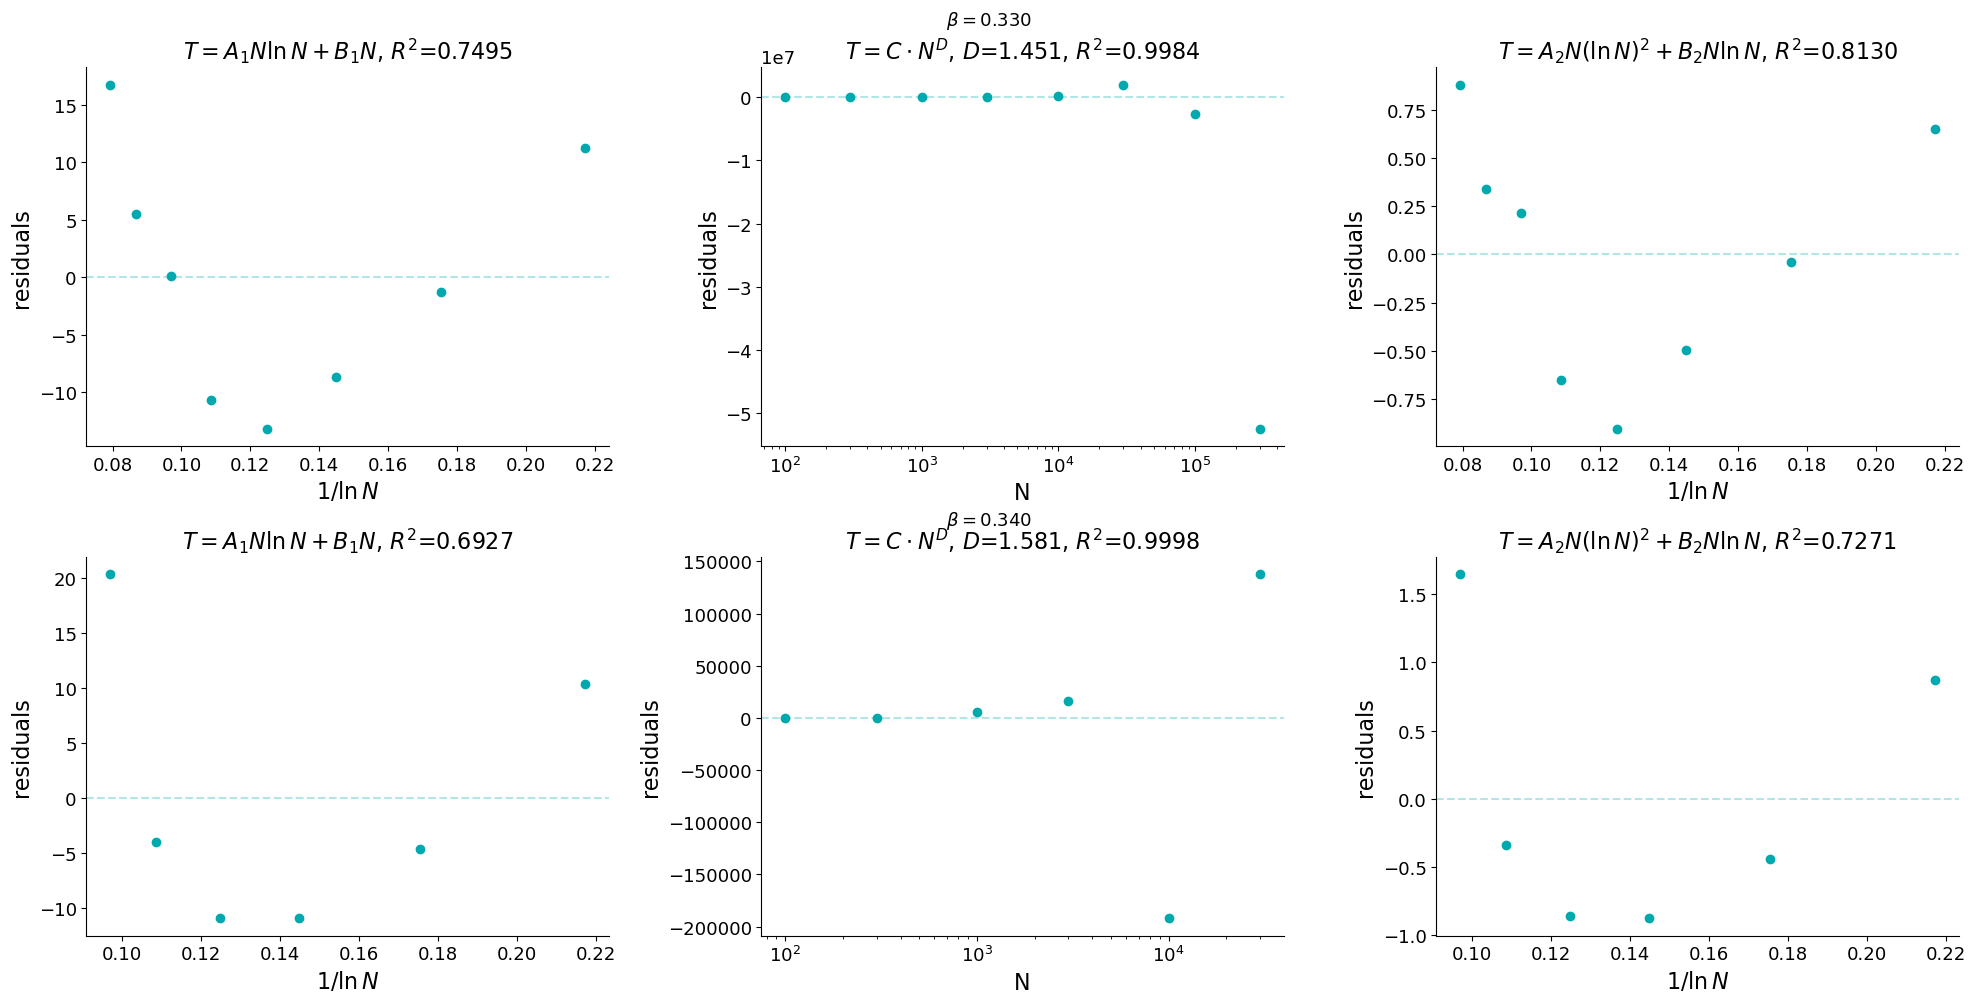

In [27]:
if graph_type == 'ER' and coup_type == 'ising':
    beta_sel_list = [0.25,0.26]
elif graph_type == 'ER' and coup_type == 'gauss':
    beta_sel_list = [0.33,0.34]
else:
    beta_sel_list = [df['beta'].unique()[0]]

print("beta_sel_list=", beta_sel_list)

n_beta = len(beta_sel_list)
fig, axes = plt.subplots(n_beta, 3, figsize=(20, 5 * n_beta), squeeze=False)

for row, beta_sel in enumerate(beta_sel_list):
    sub_df = df_filtered[df_filtered['beta'] == beta_sel].sort_values('N')
    N = sub_df['N'].values
    T = sub_df['mean_coal_time'].values

    x = 1 / np.log(N)
    y = T / (N * np.log(N))

    fc = fit_coeffs[beta_sel]

    ax0, ax1, ax2 = axes[row]

    # --- residuals of NlnN fit ---
    y_pred1 = fc['A1'] + fc['B1'] * x
    residuals1 = y - y_pred1
    ax0.axhline(0, linestyle='--', alpha=0.3)
    ax0.plot(x, residuals1, 'o')
    ax0.set_xlabel(r'$1 / \ln N$')
    ax0.set_ylabel('residuals')
    ax0.set_title(rf"$T = A_1 N\ln N + B_1 N$, $R^2$={fc['r2_NlnN']:.4f}")

    # --- residuals of power law fit ---
    y_pred2 = fc['C'] * N**fc['D']
    residuals2 = T - y_pred2
    ax1.axhline(0, linestyle='--', alpha=0.3)
    ax1.plot(N, residuals2, 'o')
    ax1.set_xscale('log')
    ax1.set_xlabel('N')
    ax1.set_ylabel('residuals')
    ax1.set_title(rf"$T = C \cdot N^D$, $D$={fc['D']:.3f}, $R^2$={fc['r2_powerlaw']:.4f}")

    # --- residuals of N(lnN)^2 fit ---
    y3 = T / (N * np.log(N)**2)
    y_pred3 = fc['A2'] + fc['B2'] * x
    residuals3 = y3 - y_pred3
    ax2.axhline(0, linestyle='--', alpha=0.3)
    ax2.plot(x, residuals3, 'o')
    ax2.set_xlabel(r'$1 / \ln N$')
    ax2.set_ylabel('residuals')
    ax2.set_title(rf"$T = A_2 N(\ln N)^2 + B_2 N\ln N$, $R^2$={fc['r2_NlnN2']:.4f}")

    fig.text(0.5, 1 - (row + 0.02) / n_beta, rf'$\beta={beta_sel:.3f}$',
              ha='center', fontsize=13, fontweight='bold')

plt.tight_layout()
plt.show()

In [28]:
for beta_sel in beta_sel_list:
    sub_df = df_filtered[df_filtered['beta'] == beta_sel].sort_values('N')
    N = sub_df['N'].values
    T = sub_df['mean_coal_time'].values

    fc = fit_coeffs[beta_sel]

    # R² of power law fit in linear space (comparable to NlnN R²)
    y_pred_linear = fc['C'] * N**fc['D']
    ss_res = np.sum((T - y_pred_linear)**2)
    ss_tot = np.sum((T - np.mean(T))**2)
    r2_powerlaw_linear = 1 - ss_res / ss_tot
    print(f"beta={beta_sel:.3f}: Power law R² in linear space: {r2_powerlaw_linear:.4f}")

beta=0.330: Power law R² in linear space: 0.9433
beta=0.340: Power law R² in linear space: 0.9998


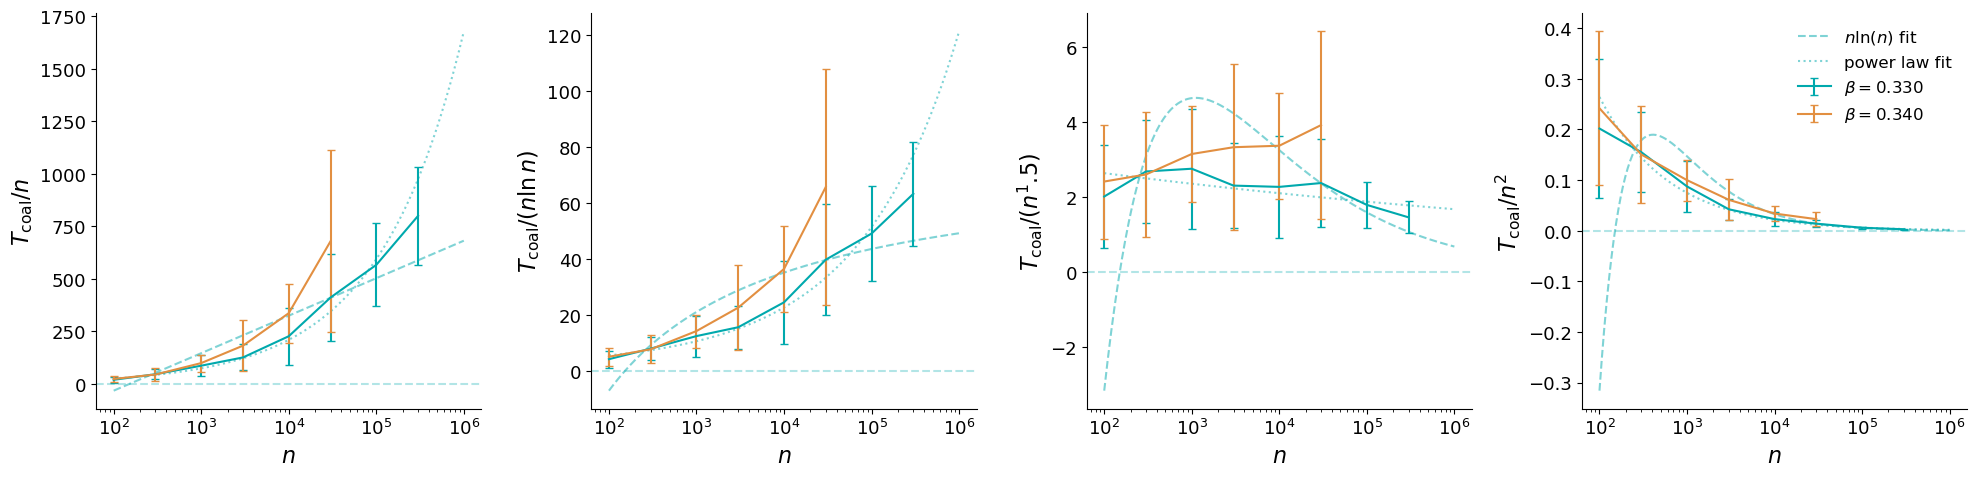

In [29]:
fig, axes = plt.subplots(1, 4, figsize=(20, 5))
scalings = {
    rf'$T_\mathrm{{coal}} / n$': (lambda N, T: T / N,
                 lambda N, T, sT: sT / N),
    rf'$T_\mathrm{{coal}} / (n \ln n)$': (lambda N, T: T / (N * np.log(N)),
                                           lambda N, T, sT: sT / (N * np.log(N))),
#    rf'$T_\mathrm{{coal}} / (n (\ln n)^2)$': (lambda N, T: T / (N * np.log(N)**2),
#                                               lambda N, T, sT: sT / (N * np.log(N)**2)),
    rf'$T_\mathrm{{coal}} / (n^{1.5})$': (lambda N, T: T / (N * np.sqrt(N)),
                                               lambda N, T, sT: sT / (N * np.sqrt(N))),
    rf'$T_\mathrm{{coal}} / n^2$': (lambda N, T: T / N**2,
                   lambda N, T, sT: sT / N**2),
}

N_fit = np.logspace(np.log10(100), np.log10(1e6), 300)  # smooth curve for fit
prop_cycle = plt.rcParams['axes.prop_cycle'].by_key()['color']

for ax, (label, (scaling_fn, err_fn)) in zip(axes, scalings.items()):
    for i, beta in enumerate(beta_sel_list):
        color = prop_cycle[i % len(prop_cycle)]

        sub_df = df_filtered[df_filtered['beta'] == beta].sort_values('N')
        N = sub_df['N'].values
        if graph_type in ('EA2D', 'F2D'):
            N = N**2
        if graph_type in ('EA3D', 'F3D'):
            N = N**3
        T = sub_df['mean_coal_time'].values
        sT = sub_df['std_coal_time'].values

        ax.errorbar(N, scaling_fn(N, T), yerr=err_fn(N, T, sT),
                    color=color, label=rf'$\beta={beta:.3f}$', capsize=3)

        fc = fit_coeffs[beta]

        if beta < beta_uni:
            # NlnN fit: T = A1*N*lnN + B1*N, plot through each scaling
            T_NlnN = fc['A1'] * N_fit * np.log(N_fit) + fc['B1'] * N_fit
            ax.plot(N_fit, scaling_fn(N_fit, T_NlnN), '--', color=color, alpha=0.5, label=r'$n\ln(n)$ fit')

            # power law fit: T = C * N**D
            T_power = fc['C'] * N_fit**fc['D']
            ax.plot(N_fit, scaling_fn(N_fit, T_power), ':', color=color, alpha=0.5, label='power law fit')

            # N(lnN)^2 fit: T = A2*N*(lnN)^2 + B2*N*lnN
            T_NlnN2 = fc['A2'] * N_fit * np.log(N_fit)**2 + fc['B2'] * N_fit * np.log(N_fit)
            #ax.plot(N_fit, scaling_fn(N_fit, T_NlnN2), '-.', color=color, alpha=0.5, label=r'$n(\ln n)^2$ fit')

    ax.axhline(0, linestyle='--', alpha=0.3)
    ax.set_xlabel(r'$n$')
    ax.set_ylabel(label)
    ax.set_xscale('log')

axes[3].legend()
plt.tight_layout()
plt.show()

In [30]:
if len(beta_sel_list)>1:
    fig.savefig(f'../results/{folder_data}/coal_DS_scaling_{graph_type}_{coup_type}_d{d}_beta{beta_sel_list[0]:.3f}_{beta_sel_list[len(beta_sel_list)-1]:.3f}.pdf', bbox_inches='tight')
else:
    fig.savefig(f'../results/{folder_data}/coal_DS_scaling_{graph_type}_{coup_type}_d{d}_beta{beta_sel_list:.3f}.pdf', bbox_inches='tight')


In [ ]:
fig, axes = plt.subplots(1, 4, figsize=(20, 5))
scalings = {
    r'$T / N$': (lambda N, T: T / N, 
                lambda N, T, sT: sT / N),
    r'$T / (N \ln N)$': (lambda N, T: T / (N * np.log(N)), 
                          lambda N, T, sT: sT / (N * np.log(N))),
    r'$T / (N \ln N^2)$': (lambda N, T: T / (N * np.log(N)**2), 
                          lambda N, T, sT: sT / (N * np.log(N)**2)),
    r'$T / N^2$': (lambda N, T: T / N**2, 
                   lambda N, T, sT: sT / N**2),
}
betas_to_exclude = [0.24]
for ax, (label, (scaling_fn, err_fn)) in zip(axes, scalings.items()):
    for beta in sorted(df_filtered['beta'].unique()):
        if beta in betas_to_exclude:
            continue
        sub_df = df_filtered[df_filtered['beta'] == beta].sort_values('N')
        N = sub_df['N'].values
        T = sub_df['mean_coal_time'].values
        sT = sub_df['std_coal_time'].values
        ax.errorbar(N, scaling_fn(N, T), yerr=err_fn(N, T, sT), label=f'beta={beta:.3f}', capsize=3)
    ax.axhline(0, linestyle='--', alpha=0.3)
    ax.set_xlabel('N')
    ax.set_ylabel(label)
    ax.set_xscale('log')   
    ax.legend(fontsize=8)
plt.show()

In [ ]:
if len(beta_sel_list)>1:
    fig.savefig(f'../results/{folder_data}/coal_scaling_{graph_type}_{coup_type}_d{d}_beta{beta_sel_list[0]:.3f}_{beta_sel_list[len(beta_sel_list)-1]:.3f}.pdf', bbox_inches='tight')
else:
    fig.savefig(f'../results/{folder_data}/coal_scaling_{graph_type}_{coup_type}_d{d}_beta{beta_sel_list:.3f}.pdf', bbox_inches='tight')
